# 02_10 Continuous Distributions: Summary and Chooser

**Learning objectives**
- Compare all Module 02 distributions in one table (support, mean, variance, skewness, tail), with numbers computed by `scipy`.
- Choose a distribution with a **decision flowchart** based on how the data are generated.
- See the **family tree**: how the distributions are built from each other (transformations, sums, ratios, limits), and check every link by simulation.
- Practice on **five short scenarios** and mixed exercises.

**Prerequisites:** lessons [02_01](02_01_uniform_normal.ipynb) to [02_09](02_09_von_mises.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

The main facts from the module, in one place:

- **Density and probability:** probability is the *area* under the PDF; the CDF is the running area; quantiles invert the CDF.
- **Normal:** sum of many small effects, mean $\mu$, SD $\sigma$; z-scores; CLT.
- **Positive and skewed:** Lognormal (products), Exponential/Gamma (waiting times), Weibull (lifetimes, hazard), Pareto (power-law tail).
- **Bounded:** Uniform on $[a,b]$; Beta on $[0,1]$ (proportions and probabilities).
- **Symmetric alternatives:** Laplace (absolute errors), Logistic (sigmoid), Cauchy (no mean), Student's t (unknown $\sigma$).
- **Extremes and directions:** Gumbel (maxima), von Mises (circular data).
- **Sampling distributions:** $\chi^2$, $t$, $F$ built from squared Normals.

## 3. Intuition and story

Choosing a distribution is like choosing a tool: look at **the job** (what does the number measure and how is it generated?) before looking at the **shape** of the histogram. Four questions settle most cases:

1. **What are the possible values?** All real numbers, only positive values, between 0 and 1, an interval $[a,b]$, or points on a circle.
2. **How is the quantity produced?** By adding many small effects (Normal), multiplying many factors (Lognormal), waiting for random events (Exponential, Gamma), or failing with aging (Weibull)? As the biggest of many (Gumbel)? As a ratio or a sum of squares (t, chi-square, F)?
3. **How heavy is the tail?** Light (Normal, Exponential), heavy (Lognormal, Pareto, Cauchy, t with few degrees of freedom)?
4. **Do the moments exist?** For heavy tails the mean or the variance may be infinite, which changes which statistics are meaningful.

The master table below puts the numbers side by side.

## 4. Formal definition: the master table

| Distribution | Support | Parameters | PDF (kernel) | Mean | Variance |
|---|---|---|---|---|---|
| Uniform | $[a,b]$ | $a,b$ | $1/(b-a)$ | $\frac{a+b}2$ | $\frac{(b-a)^2}{12}$ |
| Normal | $\mathbb R$ | $\mu,\sigma$ | $e^{-(x-\mu)^2/2\sigma^2}$ | $\mu$ | $\sigma^2$ |
| Lognormal | $x>0$ | $\mu,\sigma$ | $\frac1xe^{-(\ln x-\mu)^2/2\sigma^2}$ | $e^{\mu+\sigma^2/2}$ | $(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$ |
| Exponential | $x\ge0$ | $\lambda$ | $\lambda e^{-\lambda x}$ | $1/\lambda$ | $1/\lambda^2$ |
| Gamma | $x>0$ | $k,\theta$ | $x^{k-1}e^{-x/\theta}$ | $k\theta$ | $k\theta^2$ |
| Beta | $[0,1]$ | $\alpha,\beta$ | $x^{\alpha-1}(1-x)^{\beta-1}$ | $\frac\alpha{\alpha+\beta}$ | $\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}$ |
| Weibull | $x\ge0$ | $k,\lambda$ | $x^{k-1}e^{-(x/\lambda)^k}$ | $\lambda\Gamma(1+\frac1k)$ | $\lambda^2[\Gamma(1+\frac2k)-\Gamma(1+\frac1k)^2]$ |
| Pareto | $x\ge x_m$ | $\alpha,x_m$ | $x^{-\alpha-1}$ | $\frac{\alpha x_m}{\alpha-1}$ ($\alpha>1$) | finite if $\alpha>2$ |
| Cauchy | $\mathbb R$ | $x_0,\gamma$ | $1/(1+(\frac{x-x_0}\gamma)^2)$ | does not exist | infinite |
| Laplace | $\mathbb R$ | $\mu,b$ | $e^{-|x-\mu|/b}$ | $\mu$ | $2b^2$ |
| Logistic | $\mathbb R$ | $\mu,s$ | $F(1-F)$ | $\mu$ | $\pi^2s^2/3$ |
| Gumbel | $\mathbb R$ | $\mu,\beta$ | $e^{-z-e^{-z}}$ | $\mu+0.5772\beta$ | $\pi^2\beta^2/6$ |
| Student t | $\mathbb R$ | $\nu$ | $(1+x^2/\nu)^{-(\nu+1)/2}$ | 0 ($\nu>1$) | $\nu/(\nu-2)$ ($\nu>2$) |
| Chi-square | $x\ge0$ | $\nu$ | $x^{\nu/2-1}e^{-x/2}$ | $\nu$ | $2\nu$ |
| F | $x\ge0$ | $d_1,d_2$ | ratio of chi-squares | $\frac{d_2}{d_2-2}$ | long |
| Von Mises | circle | $\mu,\kappa$ | $e^{\kappa\cos(\theta-\mu)}$ | direction $\mu$ | $1-I_1/I_0$ |

The next cell computes mean, SD, skewness, excess kurtosis and a *tail measure* for one parameter choice each: the probability of exceeding the mean by three standard deviations (0.00135 for a Normal). Large values mean a heavy right tail.

In [2]:
catalogue = {
    "Uniform(0, 1)": stats.uniform(0, 1),
    "Normal(0, 1)": stats.norm(0, 1),
    "Lognormal(mu=0, sigma=0.8)": stats.lognorm(s=0.8, scale=1),
    "Exponential(lambda=1)": stats.expon(scale=1),
    "Gamma(k=3, theta=1)": stats.gamma(a=3, scale=1),
    "Beta(2, 5)": stats.beta(2, 5),
    "Weibull(k=1.5, lambda=1)": stats.weibull_min(1.5, scale=1),
    "Pareto(alpha=3, x_m=1)": stats.pareto(3, scale=1),
    "Laplace(0, 1)": stats.laplace(0, 1),
    "Logistic(0, 1)": stats.logistic(0, 1),
    "Gumbel(0, 1)": stats.gumbel_r(0, 1),
    "Student t(5)": stats.t(5),
    "Chi-square(5)": stats.chi2(5),
    "F(5, 10)": stats.f(5, 10),
    "Cauchy(0, 1)": stats.cauchy(0, 1),
}
rows = []
for name, dist in catalogue.items():
    mean, var, skew, kurt = dist.stats(moments="mvsk")
    sd = np.sqrt(var) if np.isfinite(var) else np.nan
    tail = dist.sf(mean + 3 * sd) if np.isfinite(sd) else np.nan
    rows.append({"distribution": name, "mean": float(mean), "SD": float(sd), "skewness": float(skew), "excess kurtosis": float(kurt), "P(X > mean + 3 SD)": tail})
master = pd.DataFrame(rows)
pd.options.display.float_format = "{:.4g}".format
print(master.to_string(index=False))

              distribution   mean     SD  skewness  excess kurtosis  P(X > mean + 3 SD)
             Uniform(0, 1)    0.5 0.2887         0             -1.2                   0
              Normal(0, 1)      0      1         0                0             0.00135
Lognormal(mu=0, sigma=0.8)  1.377  1.304     3.689            31.37             0.01867
     Exponential(lambda=1)      1      1         2                6             0.01832
       Gamma(k=3, theta=1)      3  1.732     1.155                2              0.0118
                Beta(2, 5) 0.2857 0.1597    0.5963            -0.12            0.003467
  Weibull(k=1.5, lambda=1) 0.9027 0.6129     1.072             1.39             0.01068
    Pareto(alpha=3, x_m=1)    1.5  0.866       NaN              NaN             0.01453
             Laplace(0, 1)      0  1.414         0                3            0.007185
            Logistic(0, 1)      0  1.814         0              1.2            0.004315
              Gumbel(0, 1) 0.577

**Reading the table.** Skewness 0 means symmetric (Normal, Laplace, Logistic, t, Uniform, Cauchy by symmetry). Excess kurtosis above 0 flags heavy tails (Laplace 3, Student t(5) 6, Exponential 6, Lognormal 31, F(5, 10) 51). The last column is the tail probability: 0.0013 for a Normal, about 0.015 for the Pareto(3), 0.019 for the Lognormal. `nan` means the quantity does not exist (the Cauchy has no mean or variance; the Pareto with alpha = 3 has no skewness or kurtosis).

## 5. Derivations: the family tree

Every link below was derived in its own lesson. Each is *checked by simulation* in section 9.

| Link | Statement | Lesson |
|---|---|---|
| Normal $\to$ Lognormal | $e^Y$ with $Y\sim N(\mu,\sigma^2)$ is Lognormal | 02_02 |
| Uniform $\to$ Exponential | $-\ln U/\lambda\sim\text{Exp}(\lambda)$ (inverse CDF) | 02_03 |
| Exponential $\to$ Gamma | sum of $k$ iid Exp($\lambda$) is Gamma($k,1/\lambda$) | 02_03 |
| Exponential $\to$ Weibull | $(X/\lambda)^k\sim\text{Exp}(1)$ for a Weibull | 02_05 |
| Exponential $\to$ Pareto | $\ln(X/x_m)\sim\text{Exp}(\alpha)$ for a Pareto | 02_06 |
| Exponential $\to$ Laplace | difference of two iid Exponentials | 02_07 |
| Gamma $\to$ Beta | $X/(X+Y)$ with independent Gammas | 02_04 |
| Normal $\to$ Chi-square | sum of $\nu$ squared standard normals | 02_08 |
| Normal, chi-square $\to$ t | $Z/\sqrt{\chi^2_\nu/\nu}$ | 02_08 |
| Chi-square $\to$ F | ratio of scaled chi-squares | 02_08 |
| Normal ratio $\to$ Cauchy | $Z_1/Z_2$; also Student t with $\nu=1$ | 02_06 |
| Gumbel $\to$ Logistic | difference of two iid Gumbels | 02_07 |
| Chi-square $=$ Gamma | $\chi^2_\nu=\text{Gamma}(\nu/2,2)$ | 02_03, 02_08 |
| Weibull $k=1$ | is the Exponential; $k=2$ is the Rayleigh | 02_05 |
| Beta(1,1) | is the Uniform(0,1) | 02_04 |
| Large $\nu$ | $t_\nu\to N(0,1)$, $\chi^2_\nu\approx N(\nu,2\nu)$ | 02_08 |
| Large $\kappa$ | von Mises $\to$ Normal with variance $1/\kappa$ | 02_09 |
| Maxima | max of many Exponentials $\to$ Gumbel | 02_07 |

## 6. Properties and relationships: the relationship map

The diagram shows the main arrows (transformations, sums and limits).

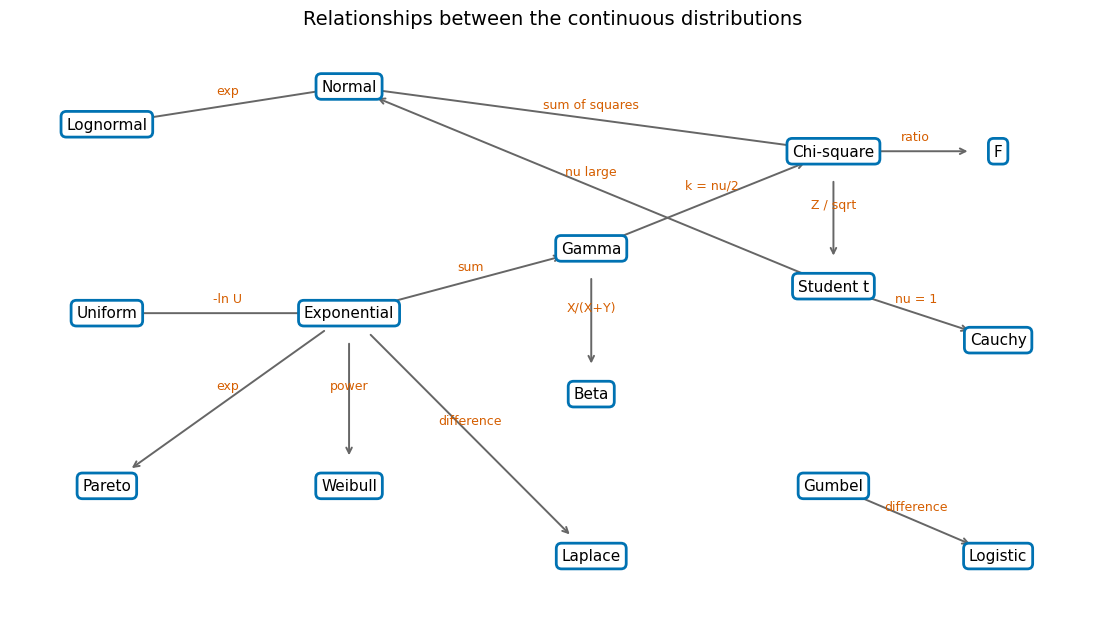

In [3]:
positions = {
    "Uniform": (0.05, 0.50), "Exponential": (0.30, 0.50), "Gamma": (0.55, 0.62), "Chi-square": (0.80, 0.80), "Beta": (0.55, 0.35),
    "Weibull": (0.30, 0.18), "Pareto": (0.05, 0.18), "Laplace": (0.55, 0.05),
    "Normal": (0.30, 0.92), "Lognormal": (0.05, 0.85), "Student t": (0.80, 0.55), "F": (0.97, 0.80), "Cauchy": (0.97, 0.45),
    "Gumbel": (0.80, 0.18), "Logistic": (0.97, 0.05),
}
links = [
    ("Uniform", "Exponential", "-ln U"), ("Exponential", "Gamma", "sum"), ("Gamma", "Chi-square", "k = nu/2"), ("Gamma", "Beta", "X/(X+Y)"),
    ("Exponential", "Weibull", "power"), ("Exponential", "Pareto", "exp"), ("Exponential", "Laplace", "difference"),
    ("Normal", "Lognormal", "exp"), ("Normal", "Chi-square", "sum of squares"), ("Chi-square", "Student t", "Z / sqrt"), ("Chi-square", "F", "ratio"),
    ("Student t", "Cauchy", "nu = 1"), ("Gumbel", "Logistic", "difference"), ("Student t", "Normal", "nu large"),
]
fig, ax = plt.subplots(figsize=(14, 7.5))
for source, target, label in links:
    (x1, y1), (x2, y2) = positions[source], positions[target]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=NEUTRAL, lw=1.4, shrinkA=22, shrinkB=22))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.02, label, ha="center", fontsize=9, color=HIGHLIGHT)
for name, (x, y) in positions.items():
    ax.text(x, y, name, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=MAIN, lw=2))
ax.set_xlim(-0.05, 1.07)
ax.set_ylim(-0.05, 1.02)
ax.axis("off")
ax.set_title("Relationships between the continuous distributions")
plt.show()

## 7. Decision flowchart: which continuous distribution?

Start at the top. Each box asks about **how the data are generated**.

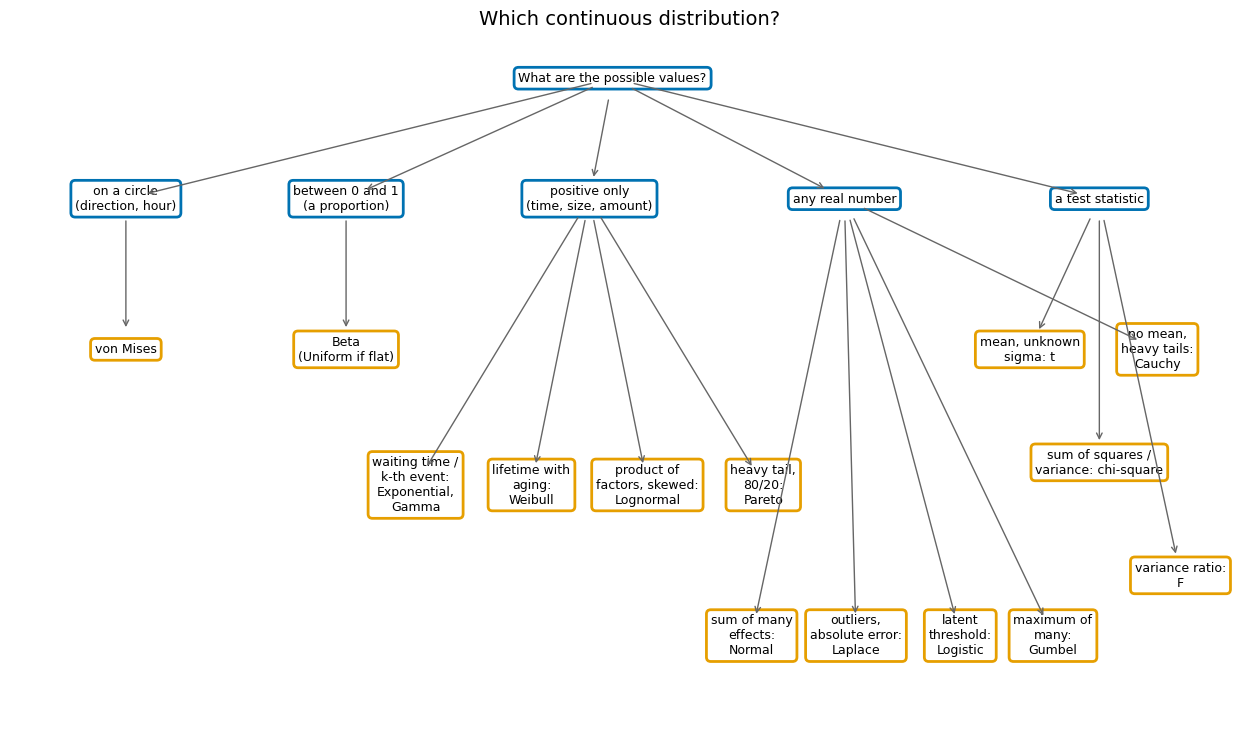

In [4]:
def draw_box(ax, x, y, text, kind="question"):
    """Draw one flowchart box: questions in blue, answers (distributions) in orange."""
    color = MAIN if kind == "question" else SIM
    ax.text(x, y, text, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=color, lw=2))

def draw_arrow(ax, x1, y1, x2, y2, label=""):
    """Draw an arrow between two boxes with a small label."""
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=NEUTRAL, shrinkA=16, shrinkB=16))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, label, fontsize=8, color=HIGHLIGHT, ha="center")

fig, ax = plt.subplots(figsize=(16, 9))
draw_box(ax, 0.5, 0.96, "What are the possible values?")
groups = [(0.08, "on a circle\n(direction, hour)"), (0.27, "between 0 and 1\n(a proportion)"), (0.48, "positive only\n(time, size, amount)"),
          (0.70, "any real number"), (0.92, "a test statistic")]
for x, label in groups:
    draw_box(ax, x, 0.80, label)
    draw_arrow(ax, 0.5, 0.96, x, 0.80)
draw_box(ax, 0.08, 0.60, "von Mises", "answer"); draw_arrow(ax, 0.08, 0.80, 0.08, 0.60)
draw_box(ax, 0.27, 0.60, "Beta\n(Uniform if flat)", "answer"); draw_arrow(ax, 0.27, 0.80, 0.27, 0.60)
positive = [(0.36, "wait for next\nevent:\nExponential"), (0.42, ""), ]
pos_answers = [(0.33, "waiting time /\nk-th event:\nExponential,\nGamma"), (0.43, "lifetime with\naging:\nWeibull"), (0.53, "product of\nfactors, skewed:\nLognormal"), (0.63, "heavy tail,\n80/20:\nPareto")]
for x, label in pos_answers:
    draw_box(ax, x, 0.42, label, "answer"); draw_arrow(ax, 0.48, 0.80, x, 0.42)
real_answers = [(0.62, "sum of many\neffects:\nNormal"), (0.71, "outliers,\nabsolute error:\nLaplace"), (0.80, "latent\nthreshold:\nLogistic"), (0.88, "maximum of\nmany:\nGumbel")]
for x, label in real_answers:
    draw_box(ax, x, 0.22, label, "answer"); draw_arrow(ax, 0.70, 0.80, x, 0.22)
draw_box(ax, 0.97, 0.60, "no mean,\nheavy tails:\nCauchy", "answer"); draw_arrow(ax, 0.70, 0.80, 0.97, 0.60)
stat_answers = [(0.86, 0.60, "mean, unknown\nsigma: t"), (0.92, 0.45, "sum of squares /\nvariance: chi-square"), (0.99, 0.30, "variance ratio:\nF")]
for x, y, label in stat_answers:
    draw_box(ax, x, y, label, "answer"); draw_arrow(ax, 0.92, 0.80, x, y)
ax.set_xlim(-0.02, 1.05)
ax.set_ylim(0.1, 1.02)
ax.axis("off")
ax.set_title("Which continuous distribution?")
plt.show()

## 8. 2D and 3D visuals

### 8.1 A gallery of shapes
Fifteen densities, each with the mean marked. Compare the supports, the skewness and the tails at a glance.

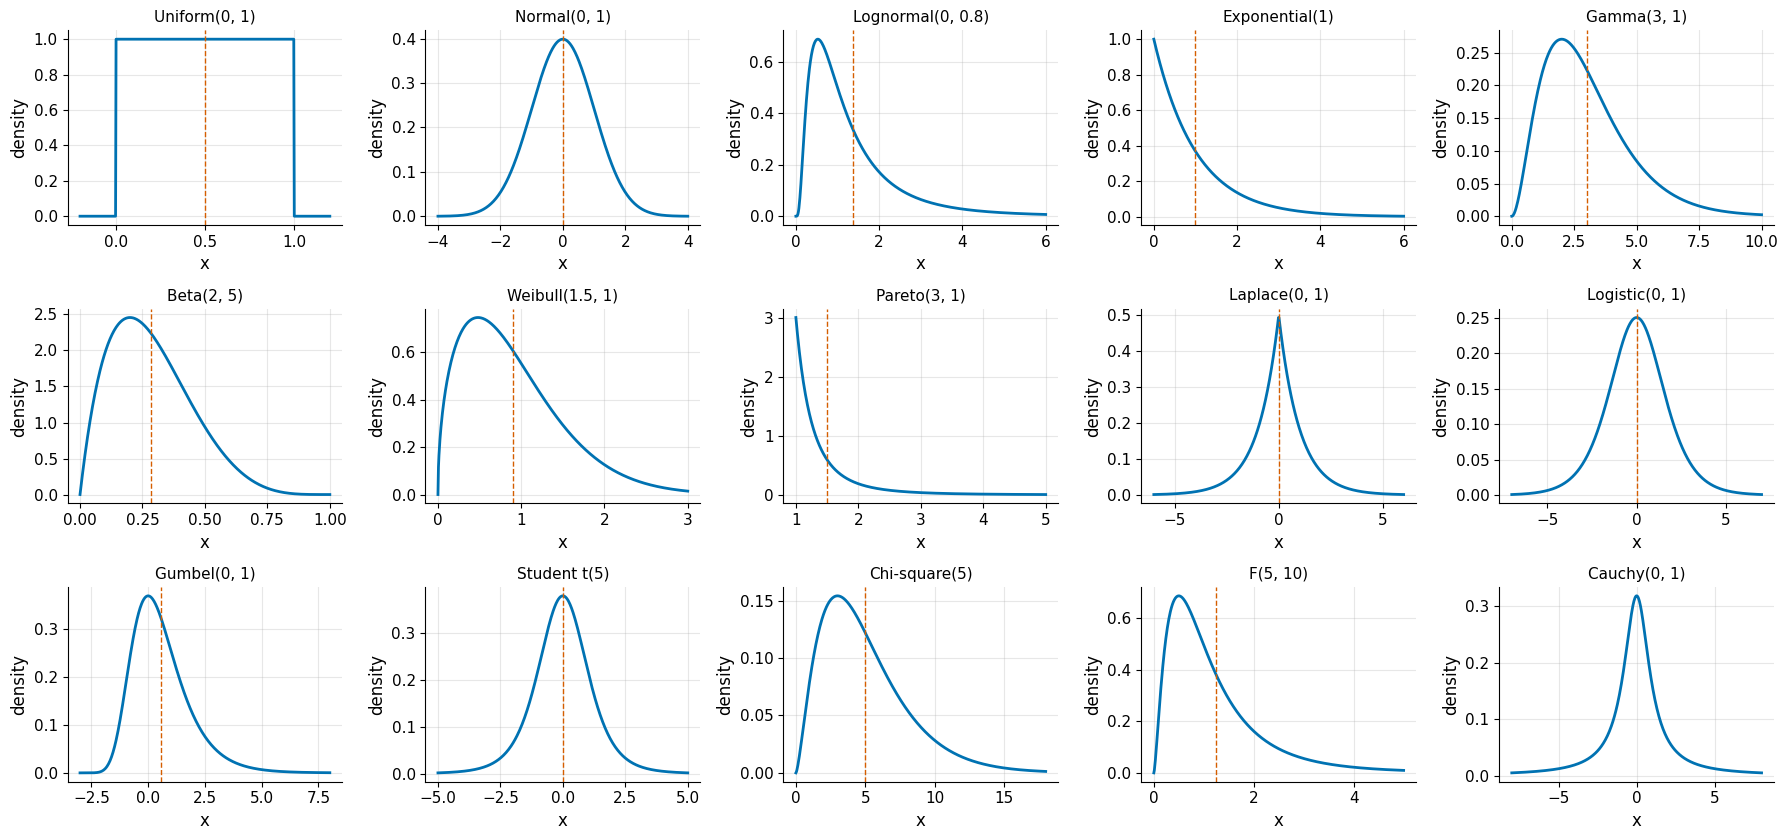

In [5]:
gallery = [
    ("Uniform(0, 1)", stats.uniform(0, 1), (-0.2, 1.2)), ("Normal(0, 1)", stats.norm(0, 1), (-4, 4)), ("Lognormal(0, 0.8)", stats.lognorm(0.8), (0, 6)),
    ("Exponential(1)", stats.expon(), (0, 6)), ("Gamma(3, 1)", stats.gamma(3), (0, 10)), ("Beta(2, 5)", stats.beta(2, 5), (0, 1)),
    ("Weibull(1.5, 1)", stats.weibull_min(1.5), (0, 3)), ("Pareto(3, 1)", stats.pareto(3), (1, 5)), ("Laplace(0, 1)", stats.laplace(), (-6, 6)),
    ("Logistic(0, 1)", stats.logistic(), (-7, 7)), ("Gumbel(0, 1)", stats.gumbel_r(), (-3, 8)), ("Student t(5)", stats.t(5), (-5, 5)),
    ("Chi-square(5)", stats.chi2(5), (0, 18)), ("F(5, 10)", stats.f(5, 10), (0, 5)), ("Cauchy(0, 1)", stats.cauchy(), (-8, 8)),
]
fig, axes = plt.subplots(3, 5, figsize=(18, 8.5))
for ax, (name, dist, (low, high)) in zip(axes.ravel(), gallery):
    grid = np.linspace(low, high, 500)
    ax.plot(grid, dist.pdf(grid), color=MAIN, linewidth=2)
    mean = dist.mean()
    if np.isfinite(mean) and low <= mean <= high:
        ax.axvline(mean, color=HIGHLIGHT, linestyle="--", linewidth=1)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("density")
plt.tight_layout()
plt.show()

### 8.2 Tails on a log axis
The survival functions of the heavy-tailed families (Pareto, Cauchy, Student t, Lognormal) drop much more slowly than the Normal's and the Exponential's. All have been scaled to have the same median distance of about 1 from the center.

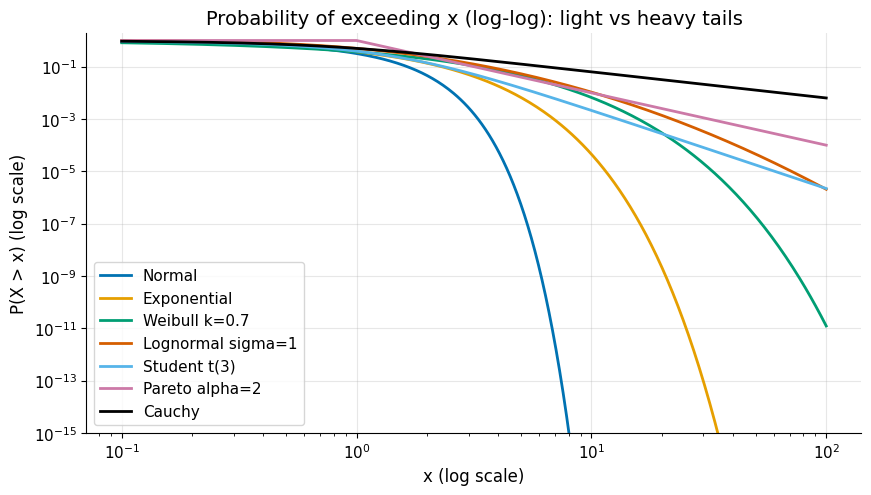

In [6]:
x_axis = np.logspace(-1, 2, 400)
tails = [("Normal", stats.norm().sf(x_axis) * 2, COLORS[0]), ("Exponential", stats.expon().sf(x_axis), COLORS[1]), ("Weibull k=0.7", stats.weibull_min(0.7).sf(x_axis), COLORS[2]),
         ("Lognormal sigma=1", stats.lognorm(1).sf(x_axis), COLORS[3]), ("Student t(3)", stats.t(3).sf(x_axis) * 2, COLORS[4]), ("Pareto alpha=2", stats.pareto(2).sf(np.maximum(x_axis, 1)), COLORS[5]), ("Cauchy", stats.cauchy().sf(x_axis) * 2, "black")]
fig, ax = plt.subplots(figsize=(10, 5.2))
for name, survival, color in tails:
    ax.loglog(x_axis, np.maximum(survival, 1e-30), linewidth=2, color=color, label=name)
ax.set_ylim(1e-15, 2)
ax.set_title("Probability of exceeding x (log-log): light vs heavy tails")
ax.set_xlabel("x (log scale)")
ax.set_ylabel("P(X > x) (log scale)")
ax.legend()
plt.show()

### 8.3 Static 3D: three one-parameter families side by side
Normal over (x, sigma), Gamma over (x, k) and Beta over (x, alpha): how each family's density changes with its main parameter.

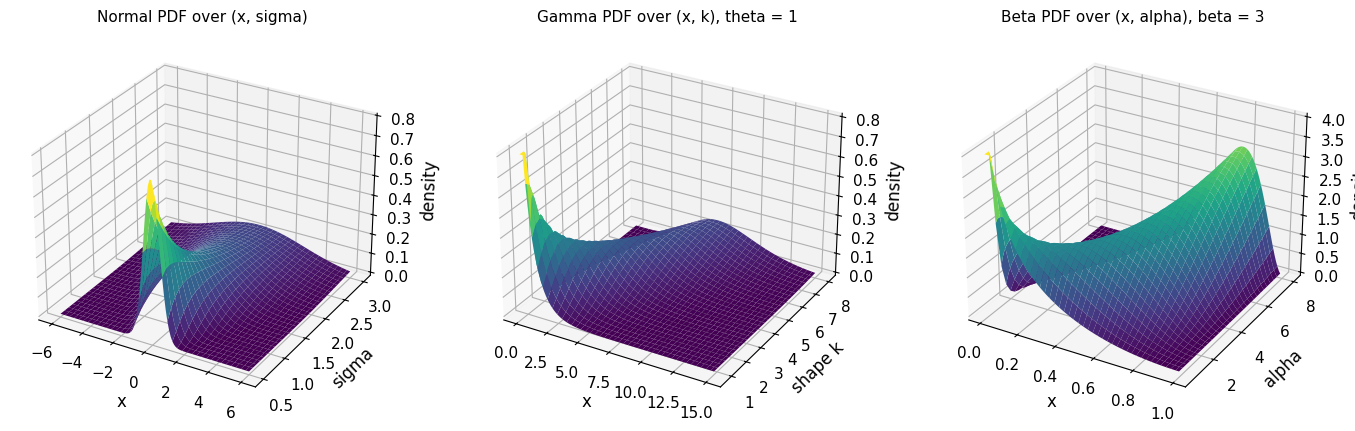

In [7]:
fig = plt.figure(figsize=(17, 5))
x1, s1 = np.meshgrid(np.linspace(-6, 6, 120), np.linspace(0.5, 3, 30))
x2, k2 = np.meshgrid(np.linspace(0.05, 15, 120), np.linspace(0.8, 8, 30))
x3, a3 = np.meshgrid(np.linspace(0.01, 0.99, 120), np.linspace(0.6, 8, 30))
surfaces = [("Normal PDF over (x, sigma)", x1, s1, stats.norm.pdf(x1, 0, s1), "sigma"),
            ("Gamma PDF over (x, k), theta = 1", x2, k2, np.minimum(stats.gamma.pdf(x2, k2), 0.8), "shape k"),
            ("Beta PDF over (x, alpha), beta = 3", x3, a3, np.minimum(stats.beta.pdf(x3, a3, 3), 4), "alpha")]
for position, (title, X, Y, Z, label) in enumerate(surfaces, start=1):
    ax = fig.add_subplot(1, 3, position, projection="3d")
    ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel(label)
    ax.set_zlabel("density")
    ax.view_init(elev=28, azim=-60)
plt.show()

### 8.4 Interactive Plotly version
Use the dropdown to switch the family; drag to rotate.

In [8]:
fig = go.Figure()
names = ["Normal over (x, sigma)", "Gamma over (x, k)", "Beta over (x, alpha)"]
fig.add_trace(go.Surface(x=np.linspace(-6, 6, 120), y=np.linspace(0.5, 3, 30), z=stats.norm.pdf(x1, 0, s1), colorscale="Viridis", visible=True))
fig.add_trace(go.Surface(x=np.linspace(0.05, 15, 120), y=np.linspace(0.8, 8, 30), z=np.minimum(stats.gamma.pdf(x2, k2), 0.8), colorscale="Plasma", visible=False))
fig.add_trace(go.Surface(x=np.linspace(0.01, 0.99, 120), y=np.linspace(0.6, 8, 30), z=np.minimum(stats.beta.pdf(x3, a3, 3), 4), colorscale="Cividis", visible=False))
buttons = [dict(label=name, method="update", args=[{"visible": [i == index for i in range(3)]}, {"title": name}]) for index, name in enumerate(names)]
fig.update_layout(title=names[0], width=800, height=560, updatemenus=[dict(buttons=buttons, direction="down", x=0.02, y=1.12)],
                  scene=dict(xaxis_title="x", yaxis_title="parameter", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory

### 9.1 The family tree by simulation
For every link in section 5 we simulate 100,000 values by the stated recipe and run a Kolmogorov-Smirnov test against the claimed distribution. A large p-value means the simulation is consistent with the claim.

In [9]:
n = 100_000
U = rng.uniform(size=n)
Z = rng.normal(size=n)
E = rng.exponential(1, size=(n, 5))
G1, G2 = rng.gamma(3, size=n), rng.gamma(2, size=n)
Zs = rng.normal(size=(n, 6))
chi5 = (Zs[:, :5] ** 2).sum(axis=1)
lam = 2.0

checks = [
    ("exp(Normal(0, 0.8)) is Lognormal", np.exp(rng.normal(0, 0.8, n)), stats.lognorm(0.8).cdf),
    ("-ln(U) / lambda is Exponential(lambda)", -np.log(U) / lam, stats.expon(scale=1 / lam).cdf),
    ("sum of 5 Exp(1) is Gamma(5, 1)", E.sum(axis=1), stats.gamma(5).cdf),
    ("(Weibull / lambda)^k is Exponential(1)", (3 * rng.weibull(1.5, n) / 3) ** 1.5, stats.expon.cdf),
    ("x_m exp(Exp(alpha)) is Pareto(alpha, x_m)", 2 * np.exp(rng.exponential(1 / 3, n)), stats.pareto(3, scale=2).cdf),
    ("Exp - Exp is Laplace(0, 1)", rng.exponential(1, n) - rng.exponential(1, n), stats.laplace().cdf),
    ("X / (X + Y) of Gamma(3), Gamma(2) is Beta(3, 2)", G1 / (G1 + G2), stats.beta(3, 2).cdf),
    ("sum of 5 squared Normals is chi-square(5)", chi5, stats.chi2(5).cdf),
    ("Z / sqrt(chi2_5 / 5) is t(5)", Zs[:, 5] / np.sqrt(chi5 / 5), stats.t(5).cdf),
    ("(chi2_5 / 5) / (chi2_8 / 8) is F(5, 8)", (chi5 / 5) / ((rng.normal(size=(n, 8)) ** 2).sum(axis=1) / 8), stats.f(5, 8).cdf),
    ("Z1 / Z2 is Cauchy", rng.normal(size=n) / rng.normal(size=n), stats.cauchy().cdf),
    ("Gumbel - Gumbel is Logistic", rng.gumbel(size=n) - rng.gumbel(size=n), stats.logistic().cdf),
    ("max of 200 Exp(1) minus ln 200 is Gumbel", rng.exponential(1, (20_000, 200)).max(axis=1) - np.log(200), stats.gumbel_r().cdf),
    ("von Mises with kappa = 50 is approximately Normal(0, 1/50)", rng.vonmises(0, 50, n), stats.norm(0, 1 / np.sqrt(50)).cdf),
]
results = []
for name, samples, cdf in checks:
    statistic, p_value = stats.kstest(samples[: 20_000], cdf)
    results.append({"link": name, "KS statistic": statistic, "p-value": p_value, "consistent": p_value > 0.001})
table = pd.DataFrame(results)
print(table.to_string(index=False))
assert table["consistent"].sum() >= len(table) - 1

                                                      link  KS statistic  p-value  consistent
                          exp(Normal(0, 0.8)) is Lognormal      0.003068   0.9915        True
                    -ln(U) / lambda is Exponential(lambda)      0.003755   0.9395        True
                            sum of 5 Exp(1) is Gamma(5, 1)      0.004032   0.8997        True
                    (Weibull / lambda)^k is Exponential(1)      0.004491   0.8128        True
                 x_m exp(Exp(alpha)) is Pareto(alpha, x_m)      0.006709   0.3274        True
                                Exp - Exp is Laplace(0, 1)      0.006996   0.2803        True
           X / (X + Y) of Gamma(3), Gamma(2) is Beta(3, 2)      0.005347   0.6147        True
                 sum of 5 squared Normals is chi-square(5)      0.006471   0.3706        True
                              Z / sqrt(chi2_5 / 5) is t(5)      0.002938   0.9951        True
                    (chi2_5 / 5) / (chi2_8 / 8) is F(5, 8)  

All links except the last (an approximation, not an identity) have large p-values: the family tree holds. The von Mises case shows a small but detectable difference, since it is only *approximately* Normal.

### 9.2 Moments by simulation
We draw 200,000 samples from each family and compare the sample mean and variance with theory (skipping those whose moments do not exist).

In [10]:
rows = []
for name, dist in catalogue.items():
    samples = dist.rvs(size=200_000, random_state=11)
    theory_mean, theory_var = dist.mean(), dist.var()
    rows.append({"distribution": name, "mean theory": theory_mean, "mean sample": samples.mean(), "variance theory": theory_var, "variance sample": samples.var()})
print(pd.DataFrame(rows).to_string(index=False))

              distribution  mean theory  mean sample  variance theory  variance sample
             Uniform(0, 1)          0.5       0.4994          0.08333          0.08346
              Normal(0, 1)            0     0.005192                1           0.9975
Lognormal(mu=0, sigma=0.8)        1.377        1.383              1.7            1.735
     Exponential(lambda=1)            1       0.9979                1           0.9966
       Gamma(k=3, theta=1)            3        3.006                3            3.014
                Beta(2, 5)       0.2857       0.2861          0.02551          0.02556
  Weibull(k=1.5, lambda=1)       0.9027       0.9013           0.3757            0.375
    Pareto(alpha=3, x_m=1)          1.5        1.499             0.75           0.7364
             Laplace(0, 1)            0    -0.004567                2            2.007
            Logistic(0, 1)            0    -0.005377             3.29            3.299
              Gumbel(0, 1)       0.5772    

The Cauchy sample mean is far from any value (no mean), and the sample variances of the heavy-tailed families (Pareto, Student t(5), F) fluctuate a lot from the theory, because their fourth moments are infinite or large: another reminder of 02_06.

## 10. `scipy.stats` cheat sheet: parameter names

In [11]:
names = pd.DataFrame([
    ("Uniform(a, b)", "stats.uniform(loc=a, scale=b-a)"), ("Normal(mu, sigma)", "stats.norm(loc=mu, scale=sigma)"),
    ("Lognormal(mu, sigma)", "stats.lognorm(s=sigma, scale=exp(mu))"), ("Exponential(lambda)", "stats.expon(scale=1/lambda)"),
    ("Gamma(k, theta)", "stats.gamma(a=k, scale=theta)"), ("Beta(alpha, beta)", "stats.beta(a=alpha, b=beta)"),
    ("Weibull(k, lambda)", "stats.weibull_min(c=k, scale=lambda)"), ("Pareto(alpha, x_m)", "stats.pareto(b=alpha, scale=x_m)"),
    ("Cauchy(x0, gamma)", "stats.cauchy(loc=x0, scale=gamma)"), ("Laplace(mu, b)", "stats.laplace(loc=mu, scale=b)"),
    ("Logistic(mu, s)", "stats.logistic(loc=mu, scale=s)"), ("Gumbel max(mu, beta)", "stats.gumbel_r(loc=mu, scale=beta)"),
    ("Student t(nu)", "stats.t(df=nu)"), ("Chi-square(nu)", "stats.chi2(df=nu)"), ("F(d1, d2)", "stats.f(dfn=d1, dfd=d2)"),
    ("von Mises(mu, kappa)", "stats.vonmises(kappa, loc=mu)"),
], columns=["distribution", "frozen scipy object"])
print(names.to_string(index=False))
print()
print("common methods: pdf, logpdf, cdf, sf, ppf, isf, rvs, mean, var, std, moment, interval, stats, entropy, fit")

        distribution                   frozen scipy object
       Uniform(a, b)       stats.uniform(loc=a, scale=b-a)
   Normal(mu, sigma)       stats.norm(loc=mu, scale=sigma)
Lognormal(mu, sigma) stats.lognorm(s=sigma, scale=exp(mu))
 Exponential(lambda)           stats.expon(scale=1/lambda)
     Gamma(k, theta)         stats.gamma(a=k, scale=theta)
   Beta(alpha, beta)           stats.beta(a=alpha, b=beta)
  Weibull(k, lambda)  stats.weibull_min(c=k, scale=lambda)
  Pareto(alpha, x_m)      stats.pareto(b=alpha, scale=x_m)
   Cauchy(x0, gamma)     stats.cauchy(loc=x0, scale=gamma)
      Laplace(mu, b)        stats.laplace(loc=mu, scale=b)
     Logistic(mu, s)       stats.logistic(loc=mu, scale=s)
Gumbel max(mu, beta)    stats.gumbel_r(loc=mu, scale=beta)
       Student t(nu)                        stats.t(df=nu)
      Chi-square(nu)                     stats.chi2(df=nu)
           F(d1, d2)               stats.f(dfn=d1, dfd=d2)
von Mises(mu, kappa)         stats.vonmises(kappa, loc=m

## 11. Real-world worked examples: 5 short scenarios

For each: **identify** the distribution and justify it, compute one probability **by hand** (explicit formula), check it against `scipy` with an `assert`, and verify with a short simulation. All numbers are illustrative.

| # | Scenario |
|---|---|
| 1 | A help desk receives tickets at random, on average one every 12 minutes. What is the probability that the next ticket arrives **more than 30 minutes** from now? |
| 2 | Online order values are skewed with median 40 and a log-scale spread $\sigma=0.7$. What share of orders is **above 100**? |
| 3 | A poll finds 54 supporters among 100 people (flat prior). What is the probability that **true support exceeds 50 %**? |
| 4 | Bolts fail with a Weibull lifetime, shape 2.2 and scale 900 hours. What is the probability a bolt **survives 1,000 hours**? |
| 5 | Ten measurements have mean 4.2 s and SD 0.5 s. What is the **95 % confidence interval** for the true mean? |

### 11.1 Identify and justify

| # | Distribution | Why |
|---|---|---|
| 1 | Exponential($\lambda=1/12$ per minute) | waiting time to the next event of a random (Poisson) arrival process; memoryless |
| 2 | Lognormal($\mu=\ln40$, $\sigma=0.7$) | positive, right-skewed amounts produced by multiplicative effects; the median is $e^\mu$ |
| 3 | Beta(55, 47) | posterior for a proportion: Beta(1,1) prior plus 54 successes and 46 failures |
| 4 | Weibull($k=2.2$, $\lambda=900$) | a lifetime with increasing hazard (wear-out), $k>1$ |
| 5 | Student t with 9 d.f. | the mean of a small sample with an estimated SD (unknown $\sigma$) |

### 11.2 By hand (explicit formulas with `math`)

In [12]:
import math

def standard_normal_cdf(z):
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))

# 1. Exponential: P(X > 30) = exp(-lambda * 30)
p1_hand = math.exp(-30 / 12)

# 2. Lognormal: P(X > 100) = 1 - Phi((ln 100 - ln 40) / 0.7)
p2_hand = 1 - standard_normal_cdf((math.log(100) - math.log(40)) / 0.7)

# 3. Beta(55, 47): P(p > 0.5) by trapezoid integration of the density (plain loop)
def beta_pdf(x, a, b):
    return math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + (a - 1) * math.log(x) + (b - 1) * math.log(1 - x))
steps = 50_000
width = 0.5 / steps
p3_hand = 0.0
previous = beta_pdf(0.5, 55, 47)
for i in range(1, steps):
    current = beta_pdf(0.5 + i * width, 55, 47)
    p3_hand += 0.5 * (previous + current) * width
    previous = current
p3_hand += 0.5 * width * 0.0        # the density is essentially 0 near 1; the loop covers 0.5 to 1.0

# 4. Weibull: S(1000) = exp(-(1000 / 900)^2.2)
p4_hand = math.exp(-((1000 / 900) ** 2.2))

# 5. t interval: mean +- t_{0.975, 9} * s / sqrt(n), with the table value 2.262
interval_hand = (4.2 - 2.262 * 0.5 / math.sqrt(10), 4.2 + 2.262 * 0.5 / math.sqrt(10))
print([round(v, 5) for v in (p1_hand, p2_hand, p3_hand, p4_hand)], np.round(interval_hand, 4))

[0.08208, 0.09527, 0.78692, 0.28341] [3.8423 4.5577]


### 11.3 In code with `scipy`, and the asserts

In [13]:
p1_code = stats.expon(scale=12).sf(30)
p2_code = stats.lognorm(s=0.7, scale=40).sf(100)
p3_code = stats.beta(55, 47).sf(0.5)
p4_code = stats.weibull_min(c=2.2, scale=900).sf(1000)
interval_code = stats.t.interval(0.95, df=9, loc=4.2, scale=0.5 / np.sqrt(10))

assert np.isclose(p1_hand, p1_code)
assert np.isclose(p2_hand, p2_code)
assert np.isclose(p3_hand, p3_code, atol=1e-4)
assert np.isclose(p4_hand, p4_code)
assert np.allclose(interval_hand, interval_code, atol=0.001)
print(pd.DataFrame({"scenario": [1, 2, 3, 4], "probability": [p1_code, p2_code, p3_code, p4_code]}).round(5).to_string(index=False))
print("scenario 5: 95 % interval =", np.round(interval_code, 4))

 scenario  probability
        1      0.08208
        2      0.09527
        3       0.7869
        4       0.2834
scenario 5: 95 % interval = [3.8423 4.5577]


### 11.4 Verify by simulation

In [14]:
trials = 500_000
sim1 = np.mean(rng.exponential(12, trials) > 30)
sim2 = np.mean(rng.lognormal(math.log(40), 0.7, trials) > 100)
sim3 = np.mean(rng.beta(55, 47, trials) > 0.5)
sim4 = np.mean(900 * rng.weibull(2.2, trials) > 1000)

# scenario 5: coverage of the t interval for samples of 10 Normal values
samples = rng.normal(4.2, 0.5, size=(200_000, 10))
means, errors = samples.mean(axis=1), samples.std(axis=1, ddof=1) / np.sqrt(10)
sim5 = np.mean(np.abs(means - 4.2) <= stats.t.ppf(0.975, 9) * errors)

for number, (exact, simulated) in enumerate([(p1_code, sim1), (p2_code, sim2), (p3_code, sim3), (p4_code, sim4)], start=1):
    print(f"scenario {number}: exact {exact:.5f}, simulated {simulated:.5f}")
    assert abs(exact - simulated) < 0.005
print(f"scenario 5: the t interval covers the true mean in {sim5:.4f} of the samples (target 0.95)")
assert abs(sim5 - 0.95) < 0.005

scenario 1: exact 0.08208, simulated 0.08185


scenario 2: exact 0.09527, simulated 0.09509
scenario 3: exact 0.78692, simulated 0.78738
scenario 4: exact 0.28341, simulated 0.28438
scenario 5: the t interval covers the true mean in 0.9508 of the samples (target 0.95)


### 11.5 Plots with the regions marked

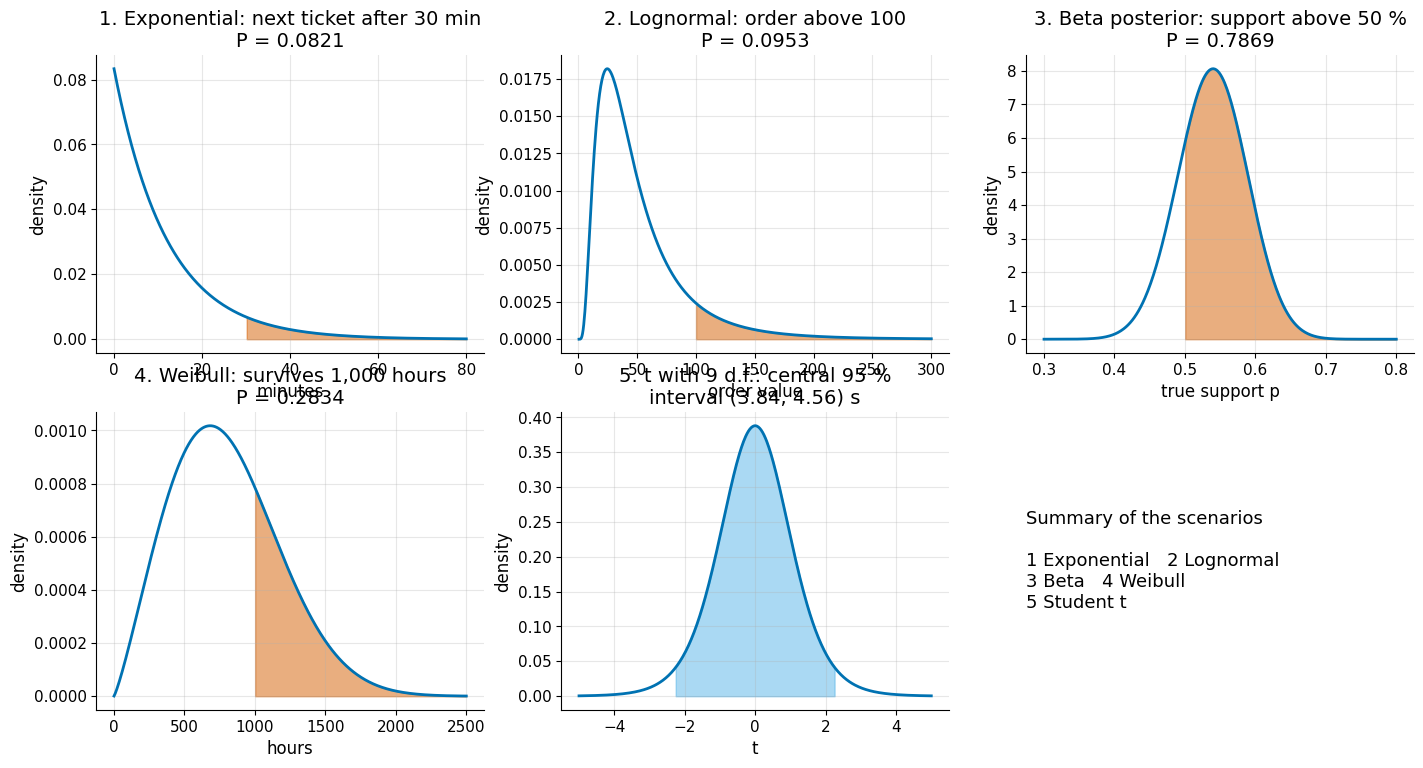

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))

def shade_region(ax, dist, grid, lower, upper, title, answer, xlabel):
    """Plot a PDF and shade the area between lower and upper."""
    ax.plot(grid, dist.pdf(grid), color=MAIN, linewidth=2)
    inside = (grid >= lower) & (grid <= upper)
    ax.fill_between(grid[inside], dist.pdf(grid[inside]), color=HIGHLIGHT, alpha=0.5)
    ax.set_title(f"{title}\n{answer}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("density")

shade_region(axes[0, 0], stats.expon(scale=12), np.linspace(0, 80, 500), 30, 80, "1. Exponential: next ticket after 30 min", f"P = {p1_code:.4f}", "minutes")
shade_region(axes[0, 1], stats.lognorm(0.7, scale=40), np.linspace(0.5, 300, 600), 100, 300, "2. Lognormal: order above 100", f"P = {p2_code:.4f}", "order value")
shade_region(axes[0, 2], stats.beta(55, 47), np.linspace(0.3, 0.8, 500), 0.5, 0.8, "3. Beta posterior: support above 50 %", f"P = {p3_code:.4f}", "true support p")
shade_region(axes[1, 0], stats.weibull_min(2.2, scale=900), np.linspace(1, 2500, 600), 1000, 2500, "4. Weibull: survives 1,000 hours", f"P = {p4_code:.4f}", "hours")

t_axis = np.linspace(-5, 5, 500)
axes[1, 1].plot(t_axis, stats.t(9).pdf(t_axis), color=MAIN, linewidth=2)
critical = stats.t.ppf(0.975, 9)
axes[1, 1].fill_between(t_axis[np.abs(t_axis) <= critical], stats.t(9).pdf(t_axis[np.abs(t_axis) <= critical]), color=COLORS[4], alpha=0.5)
axes[1, 1].set_title(f"5. t with 9 d.f.: central 95 %\ninterval ({interval_code[0]:.2f}, {interval_code[1]:.2f}) s")
axes[1, 1].set_xlabel("t")
axes[1, 1].set_ylabel("density")
axes[1, 2].axis("off")
axes[1, 2].text(0.0, 0.5, "Summary of the scenarios\n\n1 Exponential   2 Lognormal\n3 Beta   4 Weibull\n5 Student t", fontsize=13, va="center")
plt.show()

### 11.6 Interpretation and decision
1. **Tickets:** a 30-minute silence has probability **8.2 %**, about once in 12 gaps. Do not read a quiet half hour as an outage by itself; alert on longer silences or use a rate-based check.
2. **Orders:** **9.5 % of orders exceed 100**, even though the median is 40: a few big orders pull the mean (about 51) well above the median. Use medians and percentiles for pricing and shipping thresholds.
3. **Poll:** the probability that true support exceeds 50 % is only about **79 %** with 100 respondents: a 54-46 split is not decisive. A larger sample is needed to call the result.
4. **Bolts:** only **28 %** of bolts survive 1,000 hours (900 hours is the characteristic life, by which 63 % have failed); with $k>1$ the hazard rises, so replacing bolts on a schedule (before wear-out) pays off, unlike for memoryless failures.
5. **Measurements:** the true mean lies between **3.84 and 4.56 s** with 95 % confidence; the t interval is wider than a z interval because only 10 observations were used.

## 12. Where it is used

### Statistics
- Choosing the **likelihood** is the first step of every model: Normal (least squares), Lognormal (log models), Gamma/Exponential/Weibull (survival), Beta (proportions), Laplace (robust), Logistic (binary outcomes).
- **Sampling distributions** ($t$, $\chi^2$, $F$) underlie classical tests (Module 06).

### Data science
- **Describe before modelling:** histograms, log transforms, Q-Q plots, and tail checks to pick a family (Module 11).
- **Reporting:** medians and percentiles for skewed data, return levels for extremes, circular means for time-of-day.

### ML and AI
- **Losses are negative log-likelihoods:** MSE (Normal), MAE (Laplace), cross-entropy (Bernoulli, Logistic link), Poisson loss; heavy-tailed noise with Student-t.
- **Priors and latent variables:** Gaussian latent spaces (VAE), Beta/Dirichlet for probabilities, Gamma for rates, half-Cauchy for scales, von Mises-Fisher for directions.

## 13. Common pitfalls and misconceptions

- **Choosing by histogram shape alone:** many families look alike (Lognormal, Gamma and Weibull are all right-skewed). Decide from the data-generating story, then compare fits (log-likelihood, AIC, Q-Q plots).
- **Ignoring the support:** a Normal can give negative times or proportions above 1; use a distribution whose support matches the quantity.
- **Parameter conventions:** `scipy` uses scale, not rate (Exponential, Gamma); Lognormal uses s and scale = exp(mu); Weibull uses c; Pareto uses b.
- **Moments that do not exist:** Cauchy has no mean; Pareto with alpha at most 2 has an infinite variance. Prefer the median and quantiles there.
- **Treating sampling distributions as data models:** t, chi-square and F describe statistics, not raw data.
- **Fitting then trusting the tail:** a distribution fitted to the bulk can badly misjudge extremes (Example 3 of 02_06).

## 14. Exercises (mixed practice)

For each: name the distribution, then compute the answer.

1. The time between two earthquakes in a region averages 40 days (Poisson process). Probability of more than 100 days between two quakes?
2. Heights of adult women are Normal with mean 162 cm and SD 6 cm. What proportion is shorter than 150 cm? What height marks the 95th percentile?
3. A hospital's length of stay is right-skewed with a median of 4 days and a log-scale SD of 0.6. What proportion of stays exceeds 10 days?
4. A new feature converts 18 of 120 users. With a flat prior, what is the posterior mean of the conversion rate, and the probability it exceeds 10 %?
5. The maximum yearly wind gust at a site is Gumbel with $\mu=30$ m/s and $\beta=4$ m/s. What is the 50-year return level?
6. Fifteen items from a machine have sample SD 0.8 mm, against a claimed SD of 0.5 mm. Compute the chi-square statistic and the p-value (upper tail).
7. (Harder) Residuals of a model have many outliers. Which of the Normal, Laplace and Cauchy has a log-density that grows linearly (rather than quadratically) in the error, and what does that mean for the loss?
8. (Harder) A customer's daily peak activity hour has circular mean 21:30 and mean resultant length 0.6. Estimate $\kappa$ (numerically) and say what share of activity falls within 2 hours of the peak.

Solutions are at the end.

## 15. Summary table

| Family | Use when | Key parameters | `scipy` |
|---|---|---|---|
| Uniform | no preference within a range; random numbers | a, b | `uniform(a, b-a)` |
| Normal | sums and averages; measurement error | mu, sigma | `norm` |
| Lognormal | positive skewed, multiplicative | mu, sigma of ln X | `lognorm(s, scale)` |
| Exponential | time to the next random event | lambda | `expon(scale)` |
| Gamma / Erlang | time to the k-th event; positive amounts | k, theta | `gamma(a, scale)` |
| Beta | proportions, probabilities | alpha, beta | `beta` |
| Weibull | lifetimes with aging | k, lambda | `weibull_min(c, scale)` |
| Pareto | power-law tails, 80/20 | alpha, x_m | `pareto(b, scale)` |
| Cauchy | ratios of Normals; stress tests | x0, gamma | `cauchy` |
| Laplace | absolute errors, robust fits | mu, b | `laplace` |
| Logistic | latent threshold, sigmoid | mu, s | `logistic` |
| Gumbel | maxima, return levels | mu, beta | `gumbel_r` |
| Student t | mean with unknown sigma | nu | `t` |
| Chi-square | variance, goodness of fit | nu | `chi2` |
| F | ratio of variances, ANOVA | d1, d2 | `f` |
| Von Mises | directions, time of day | mu, kappa | `vonmises` |

## Solutions

In [16]:
print("1: Exponential, P(> 100 days) =", round(math.exp(-100 / 40), 4))
women = stats.norm(162, 6)
print("2: Normal, P(< 150) =", round(women.cdf(150), 4), "; 95th percentile =", round(women.ppf(0.95), 2), "cm")
print("3: Lognormal, P(stay > 10) =", round(stats.lognorm(0.6, scale=4).sf(10), 4))
post = stats.beta(1 + 18, 1 + 102)
print("4: Beta(19, 103): mean =", round(post.mean(), 4), " P(> 10 %) =", round(post.sf(0.10), 4))
print("5: Gumbel 50-year level =", round(stats.gumbel_r(30, 4).ppf(1 - 1 / 50), 2), "m/s")
chi6 = 14 * 0.8**2 / 0.5**2
print("6: chi-square =", round(chi6, 3), " p-value =", round(stats.chi2(14).sf(chi6), 5))
from scipy import optimize, special
kappa8 = optimize.brentq(lambda k: special.i1(k) / special.i0(k) - 0.6, 0.01, 50)
d8 = stats.vonmises(kappa8)
print("8: kappa =", round(kappa8, 3), " P(within 2 h = +-30 degrees) =", round(d8.cdf(np.pi / 6) - d8.cdf(-np.pi / 6), 4))

1: Exponential, P(> 100 days) = 0.0821
2: Normal, P(< 150) = 0.0228 ; 95th percentile = 171.87 cm
3: Lognormal, P(stay > 10) = 0.0634
4: Beta(19, 103): mean = 0.1557  P(> 10 %) = 0.9679
5: Gumbel 50-year level = 45.61 m/s
6: chi-square = 35.84  p-value = 0.0011
8: kappa = 1.516  P(within 2 h = +-30 degrees) = 0.4271


**1.** Exponential with mean 40 days: $P(>100)=e^{-100/40}=e^{-2.5}=0.0821$.

**2.** Normal: $P(<150)=\Phi(-2)=0.0228$; the 95th percentile is $162+1.645\times6=171.9$ cm.

**3.** Lognormal with $\mu=\ln4$, $\sigma=0.6$: $z=(\ln10-\ln4)/0.6=1.527$, $P(>10)=0.0634$.

**4.** Beta(19, 103): mean $19/122=0.156$; $P(\text{rate}>10\%)=0.97$ (printed).

**5.** $x_{50}=\mu-\beta\ln(-\ln(1-1/50))=30+4\times3.902=45.6$ m/s.

**6.** $\chi^2=14\times0.64/0.25=35.84$ with 14 d.f.; the upper-tail p-value is about 0.001: the machine is far more variable than claimed.

**7.** The Laplace (log-density $-|x-\mu|/b$, linear) and the Cauchy (log-density $-\ln(1+x^2)$, grows only logarithmically) are less sensitive to outliers than the Normal (log-density quadratic). The Laplace corresponds to **L1 loss** (MAE), the Cauchy to a loss that effectively ignores very large errors.

**8.** $\kappa\approx1.52$ for $\bar R=0.6$; about 43 % of the activity lies within 2 hours of the peak (a $\pm30^\circ$ window).